In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import glob
import numpy as np
import scipy as sp
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import astropy
from astropy.io import fits
import astropy.wcs
from astropy import units as u
from astropy.coordinates import SkyCoord


In [3]:
from reproject import reproject_interp
from utils import get_imgarr, get_median, get_vmin_vmax, get_mean_pix

In [11]:
### Read in Models
#lcpath = './data/'
#lcpath = '../python_fitting/LC_tables/models/'

lcpath = '../emcee_fitting/LC_tables/models/'

#lcpath = './emcee_fitting/LC_tables/models/seperate_fit/' # path mcmc fit seperatelatey each bands, keep tshift same

# new model using MCMC
LCm2_i = pd.read_csv(lcpath +'iLC_mod2.csv')
LCm2_g = pd.read_csv(lcpath +'gLC_mod2.csv')
LCm2_r = pd.read_csv(lcpath +'rLC_mod2.csv')
LCm2_z = pd.read_csv(lcpath +'zLC_mod2.csv')

LCdat2_i = pd.read_csv(lcpath +'iLC_data2.csv')
LCdat2_g = pd.read_csv(lcpath +'gLC_data2.csv')
LCdat2_r = pd.read_csv(lcpath +'rLC_data2.csv')
LCdat2_z = pd.read_csv(lcpath +'zLC_data2.csv')



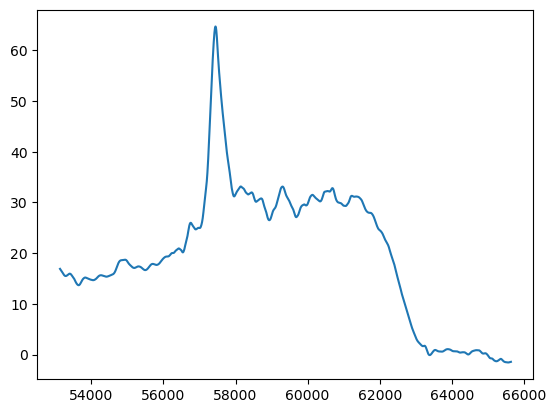

In [18]:
x = LCm2_i.mjd
y = LCm2_i.muJyas2

plt.plot(x, y)



In [134]:
lc_model_i = sp.interpolate.interp1d(LCm2_i.mjd, LCm2_i.muJyas2, kind='nearest', bounds_error=False, fill_value=0)

lc_model_g = sp.interpolate.interp1d(LCm2_g.mjd, LCm2_g.muJyas2, kind='nearest', bounds_error=False, fill_value=0)



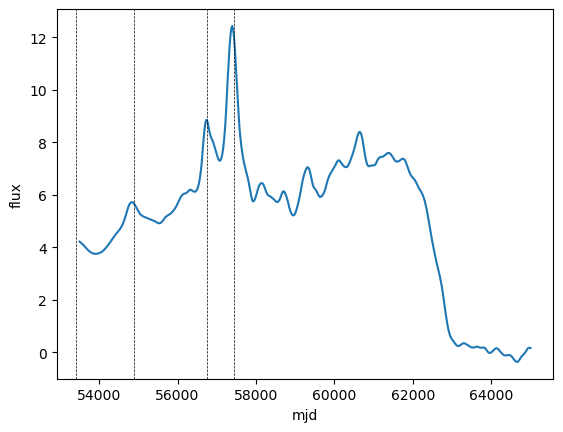

In [135]:
#t = np.linspace(51394, 65960, 500)
t = np.linspace(53500, 65000, 500)

f = lc_model_g(t)

plt.plot(t, f)

plt.xlabel('mjd')
plt.ylabel('flux')

plt.axvline(x=54900, color='k', lw=.5, ls='--')
plt.axvline(x=56750, color='k', lw=.5, ls='--')
plt.axvline(x=57430, color='k', lw=.5, ls='--')
plt.axvline(x=53400, color='k', lw=.5, ls='--')

#plt.xlim([54000, 58000])



In [136]:
( np.random.randn(n_lc)*10 )

array([  1.24309747,  -6.68692907,  10.58770291,   5.31194679,
        -2.11574561,  10.01181909,  -4.4855103 ,  -7.40315373,
        11.67564032, -19.73491975])

In [163]:
n_lc = 10

a_norm = np.random.rand(n_lc) + 0.5

f_echo = np.outer(a_norm, f) 

f_bg = np.array([100]*n_lc) + np.random.randn(n_lc)*10

f_echo_bg = f_echo + f_bg[:, np.newaxis]



In [164]:
t_echo = np.array([200]*n_lc) + np.random.randn(n_lc)*0


In [165]:
tshift = np.random.rand(n_lc) * 3000

In [166]:
t.max() - t.min()

11500.0

In [211]:
df_seg1 = pd.DataFrame(columns=['mjd', 'flux', 'flux_err', 'fieldID'])
df_seg2 = pd.DataFrame(columns=['mjd', 'flux', 'flux_err', 'fieldID'])
df_seg3 = pd.DataFrame(columns=['mjd', 'flux', 'flux_err', 'fieldID'])
df_seg4 = pd.DataFrame(columns=['mjd', 'flux', 'flux_err', 'fieldID'])



/var/folders/yb/hm0wbr8128v_fbvy474l5s6m0000gn/T/ipykernel_4237/2382033855.py:15: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_seg1 = pd.concat([df_seg1, df_id], ignore_index=True)
/var/folders/yb/hm0wbr8128v_fbvy474l5s6m0000gn/T/ipykernel_4237/2382033855.py:30: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  df_seg2 = pd.concat([df_seg2, df_id], ignore_index=True)
/var/folders/yb/hm0wbr8128v_fbvy474l5s6m0000gn/T/ipykernel_4237/2382033855.py:45: FutureWarning: The behavior of DataFrame concate

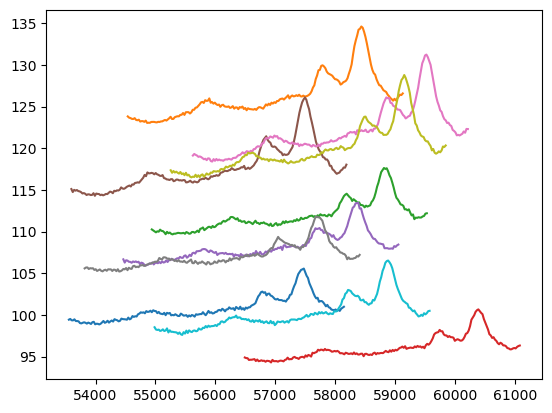

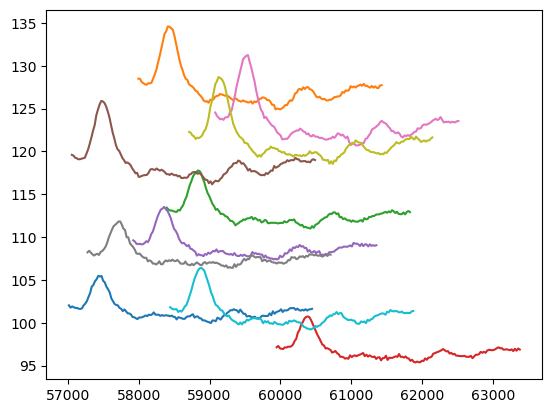

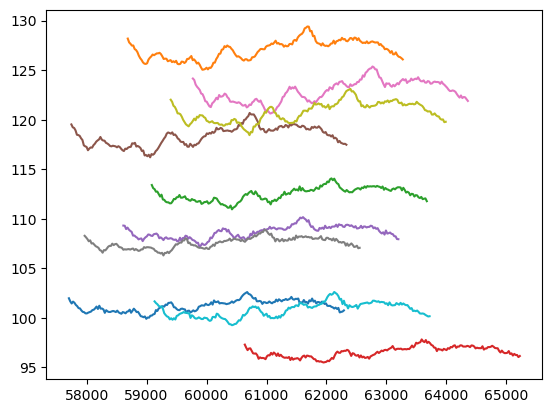

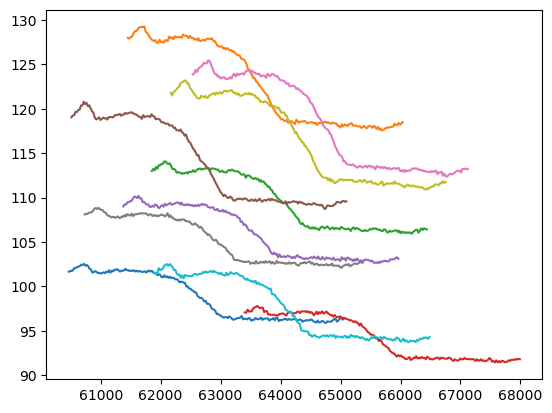

In [212]:
# :200, 150:300, 180:380, 300:500

plt.figure()

for i in range(n_lc):

    t_echo = t + tshift[i]
    t_lc = t_echo[:200]
    f_lc_err = np.random.randn(200) * 0.1
    f_lc = f_echo_bg[i,:200] + f_lc_err
    plt.plot(t_lc, f_lc, )

    df_id = pd.DataFrame({"mjd": t_lc, "flux":f_lc, "flux_err": np.abs(f_lc_err), "fieldID":[i]*200})

    df_seg1 = pd.concat([df_seg1, df_id], ignore_index=True)


plt.figure()

for i in range(n_lc):

    t_echo = t + tshift[i]
    t_lc = t_echo[150:300]
    f_lc_err = np.random.randn(150) * 0.1
    f_lc = f_echo_bg[i,150:300] + f_lc_err
    plt.plot(t_lc, f_lc, )

    df_id = pd.DataFrame({"mjd": t_lc, "flux":f_lc, "flux_err": np.abs(f_lc_err), "fieldID":[i]*150})

    df_seg2 = pd.concat([df_seg2, df_id], ignore_index=True)


plt.figure()

for i in range(n_lc):

    t_echo = t + tshift[i]
    t_lc = t_echo[180:380]
    f_lc_err = np.random.randn(200) * 0.1
    f_lc = f_echo_bg[i,180:380] + f_lc_err
    plt.plot(t_lc, f_lc, )

    df_id = pd.DataFrame({"mjd": t_lc, "flux":f_lc, "flux_err": np.abs(f_lc_err), "fieldID":[i]*200})

    df_seg3 = pd.concat([df_seg3, df_id], ignore_index=True)

plt.figure()

for i in range(n_lc):

    t_echo = t + tshift[i]
    t_lc = t_echo[300:500]
    f_lc_err = np.random.randn(200) * 0.1
    f_lc = f_echo_bg[i,300:500] + f_lc_err
    plt.plot(t_lc, f_lc, )

    df_id = pd.DataFrame({"mjd": t_lc, "flux":f_lc, "flux_err": np.abs(f_lc_err), "fieldID":[i]*200})

    df_seg4 = pd.concat([df_seg4, df_id], ignore_index=True)



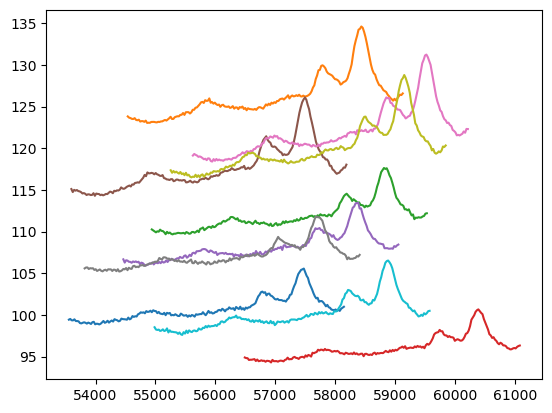

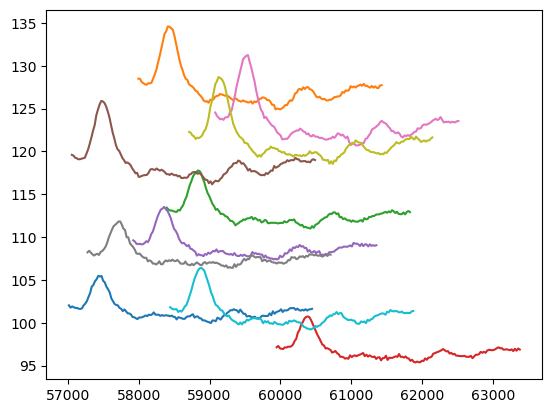

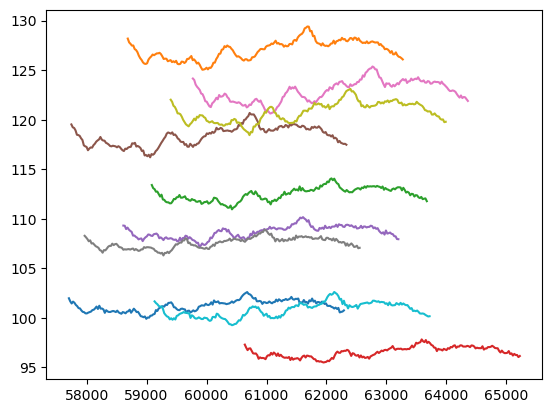

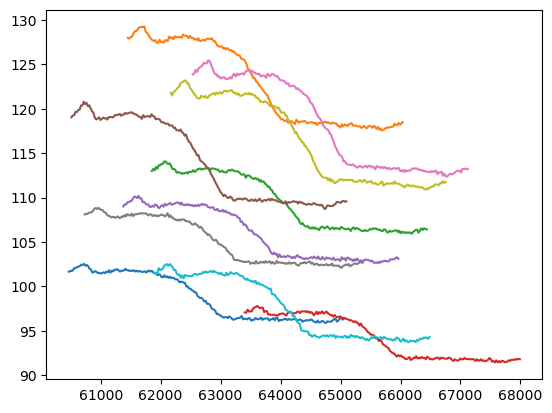

In [214]:

plt.figure()

for i in range(n_lc):
    idx = df_seg1['fieldID']==i
    t_lc = df_seg1[idx]['mjd']
    f_lc = df_seg1[idx]['flux']
    plt.plot(t_lc, f_lc, )




plt.figure()

for i in range(n_lc):
    idx = df_seg2['fieldID']==i
    t_lc = df_seg2[idx]['mjd']
    f_lc = df_seg2[idx]['flux']
    plt.plot(t_lc, f_lc, )




plt.figure()

for i in range(n_lc):
    idx = df_seg3['fieldID']==i
    t_lc = df_seg3[idx]['mjd']
    f_lc = df_seg3[idx]['flux']
    plt.plot(t_lc, f_lc, )



plt.figure()

for i in range(n_lc):
    idx = df_seg4['fieldID']==i
    t_lc = df_seg4[idx]['mjd']
    f_lc = df_seg4[idx]['flux']
    plt.plot(t_lc, f_lc, )


In [216]:
df_seg1.to_csv("data_sim/df_seg1.csv", index=False)
df_seg2.to_csv("data_sim/df_seg2.csv", index=False)
df_seg3.to_csv("data_sim/df_seg3.csv", index=False)
df_seg4.to_csv("data_sim/df_seg4.csv", index=False)



In [215]:
pwd


'/Users/home/Documents/EtaCarEchoes/old_vers1'

In [ ]:
lc_model_i()